# Adult income dataset

**Названия столбцов с пояснением:**
- **age** - Возраст в годах.
- **workclass** - Тип работодателя (частный сектор, госслужба, самозанятость и т.д.).
- **fnlwgt** - Статистический вес респондента.
- **education** - Уровень образования (от дошкольного до доктора наук).
- **education-num** - Количество лет формального обучения.
- **marital-status** - Семейное положение (в браке, разведен, никогда не был в браке и т.д.).
- **occupation** - Род занятий / профессия.
- **relationship** - Роль в семье (муж, жена, ребенок, не родственник и т.д.).
- **race** - Раса.
- **sex** - Пол (Male / Female).
- **capital-gain** - Прирост капитала (доход от продажи активов) за год в $.
- **capital-loss** - Потеря капитала (убыток от продажи активов) за год в $.
- **hours-per-week** - Количество рабочих часов в неделю.
- **native-country** - Страна происхождения.
- **income** - Доход за год: `<=50K` или `>50K`  - **ТАРГЕТ**


 


In [1]:
# Необходимо для корректной работы внешних .py файлов
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import seaborn as sns
from helper import *
from plots import *
import random

In [3]:
# фиксируем состояние генератора псевдослучайных чисел. Это необходимо, чтобы результаты модели не менялись с каждым новым запуском 
SEED = 42 # можно указать любое число
np.random.seed(SEED)
random.seed(SEED)

##  1. Изучение структуры данных

In [4]:
df = pd.read_csv("adult.csv")
df.head(5)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [6]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


## 2. Проверка на корректность и качество данных

### 2.1 Проверка на дубликаты

In [7]:
df.duplicated().sum()

np.int64(52)

In [8]:
# Удаляем дубликаты
df.drop_duplicates(inplace=True)

df.duplicated().sum()

np.int64(0)

### 2.2 Пропущенные значения

In [9]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

Пропущенных значений нет

### 2.3 Корректность по столбцам

In [10]:
# Убедимся, что нет отрицательного возраста
len(df[df['age'] < 0])

0

In [11]:
df['workclass'].value_counts()

workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
?                    2795
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

In [12]:
df['workclass'] = df['workclass'].replace('?', np.nan)


In [13]:
# Убедимся, что вес выборки (fnlwgt) положительный и не равен нулю
len(df[df['fnlwgt'] <= 0])

0

In [14]:
df['education'].value_counts()

education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
9th               756
12th              655
Doctorate         594
5th-6th           507
1st-4th           245
Preschool          81
Name: count, dtype: int64

In [15]:
# Проверим количество уникальных уровней образования
df['educational-num'].value_counts()

educational-num
9     15770
10    10863
13     8013
14     2656
11     2060
7      1812
12     1601
6      1389
4       954
15      834
5       756
8       655
16      594
3       507
2       245
1        81
Name: count, dtype: int64

In [16]:
# Убедимся, что капитал (gain/loss) не отрицательный
len(df[df['capital-gain'] < 0])

0

In [17]:
len(df[df['capital-loss'] < 0])

0

In [18]:
# Убедимся, что часов работы не больше 168 (24 часа * 7 дней)
len(df[df['hours-per-week'] > 168])


0

In [19]:
# Проверим семейное положение на наличие странных категорий 
df['marital-status'].value_counts()

marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

In [20]:
# Проверим профессию
df['occupation'].value_counts()

occupation
Prof-specialty       6165
Craft-repair         6102
Exec-managerial      6082
Adm-clerical         5606
Sales                5501
Other-service        4919
Machine-op-inspct    3017
?                    2805
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1485
Tech-support         1445
Protective-serv       982
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

In [21]:
df['occupation'] = df['occupation'].replace('?', np.nan)


In [22]:
# Проверим родство 
df['relationship'].value_counts()

relationship
Husband           19703
Not-in-family     12557
Own-child          7569
Unmarried          5124
Wife               2331
Other-relative     1506
Name: count, dtype: int64

In [23]:
# Проверим расу
df['race'].value_counts()

race
White                 41714
Black                  4683
Asian-Pac-Islander     1517
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64

In [24]:
# Убедимся, что пол (gender) представлен только двумя значениями
df['gender'].value_counts()

gender
Male      32614
Female    16176
Name: count, dtype: int64

In [25]:
# Проверим страну происхождения 
df['native-country'].value_counts()

native-country
United-States                 43792
Mexico                          943
?                               856
Philippines                     294
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Poland                           87
Vietnam                          86
Guatemala                        86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Nicaragua                        49
Greece                           49
Peru         

In [26]:
df['native-country'] = df['native-country'].replace('?', np.nan)

In [27]:
# Проверим целевую переменную
df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

В категориальных столбцах workclass, occupation, native-country есть "?", оставим как есть 

## 3. Детальное изучение признаков (и таргета)

### 3.1 Числовые переменные

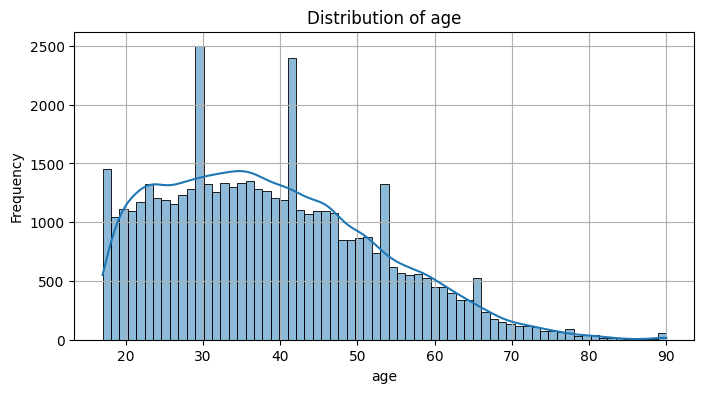

In [28]:
# Строим гистограмму распределения ApplicantIncome
plot_hist_numeric(df, 'age')

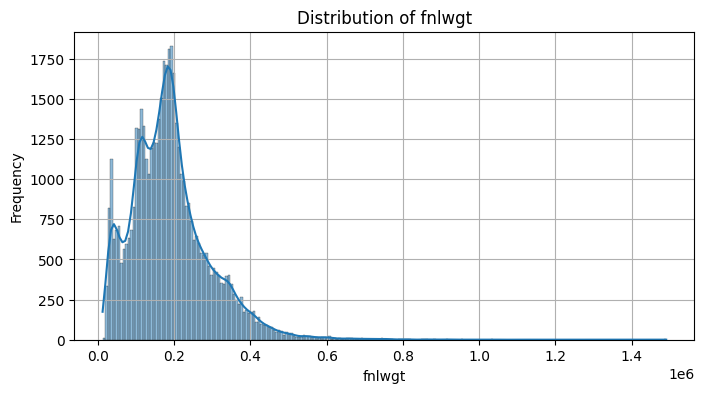

In [29]:
plot_hist_numeric(df, 'fnlwgt')

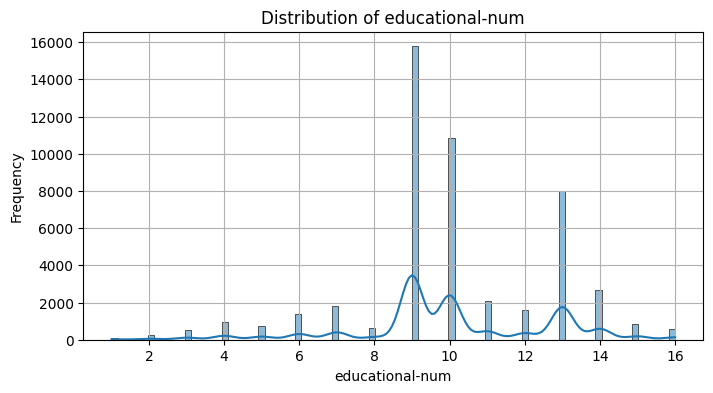

In [30]:
plot_hist_numeric(df, 'educational-num')

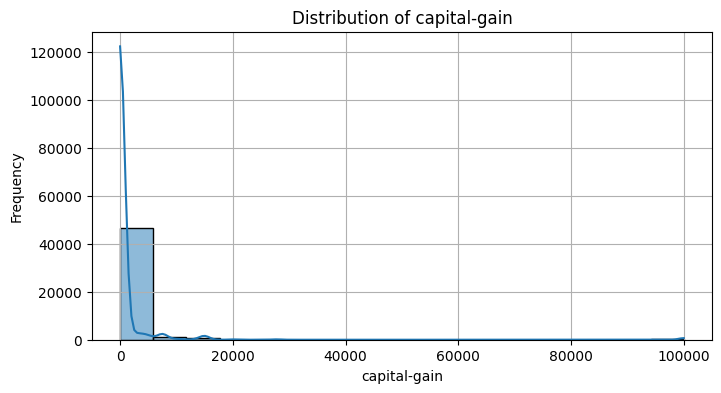

In [31]:
plot_hist_numeric(df, 'capital-gain')

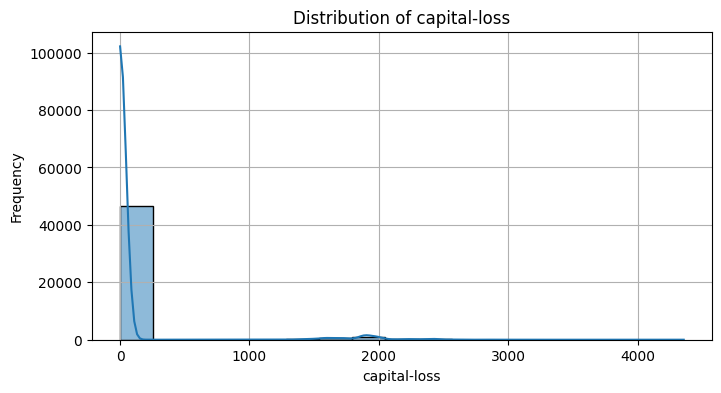

In [32]:
plot_hist_numeric(df, 'capital-loss')

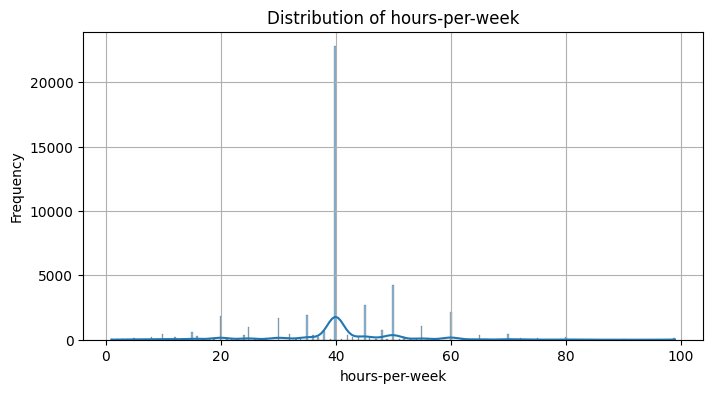

In [33]:
plot_hist_numeric(df, 'hours-per-week')

### 3.2 Категориальные переменные

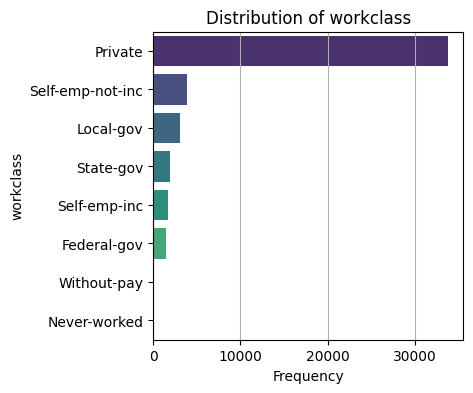

In [34]:
plot_hist_categorical(df, 'workclass')

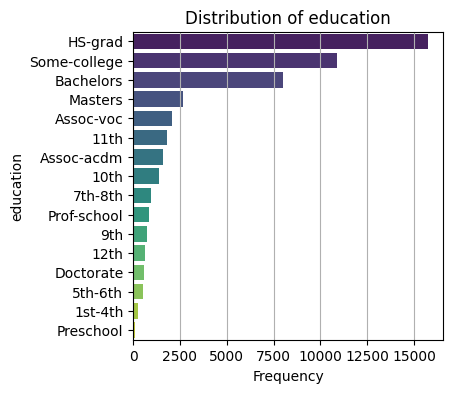

In [35]:
plot_hist_categorical(df, 'education')

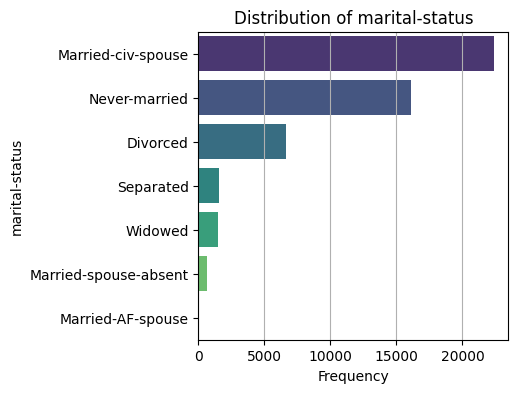

In [36]:
plot_hist_categorical(df, 'marital-status')

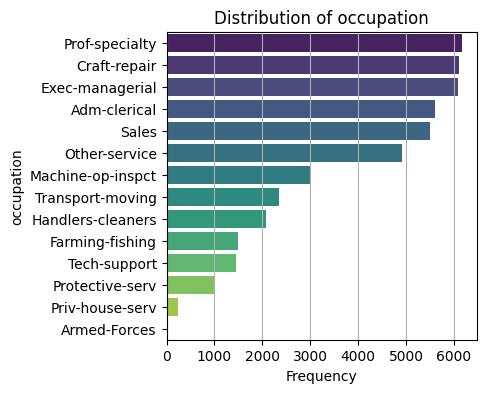

In [37]:
plot_hist_categorical(df, 'occupation')

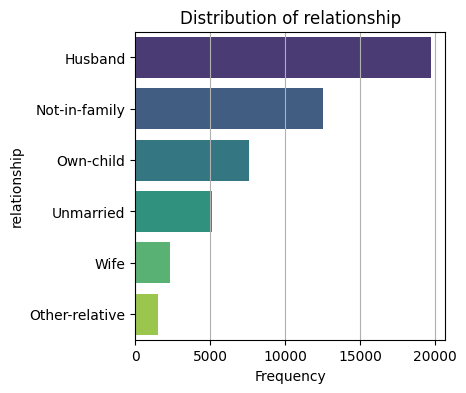

In [38]:
plot_hist_categorical(df, 'relationship')

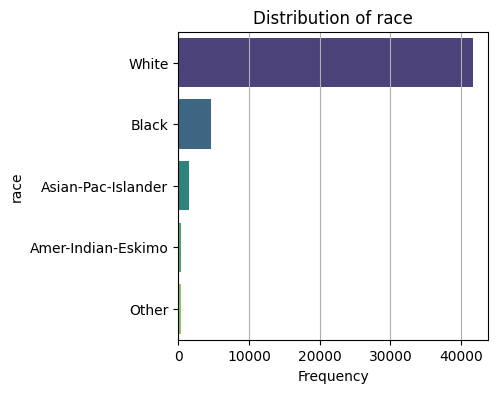

In [39]:
plot_hist_categorical(df, 'race')

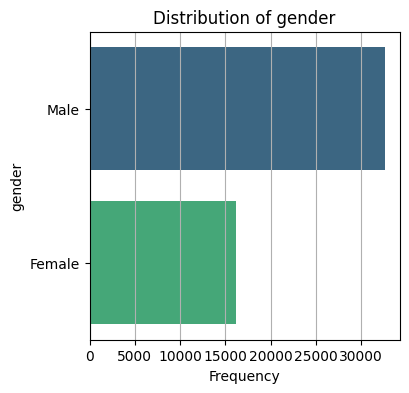

In [40]:
plot_hist_categorical(df, 'gender')

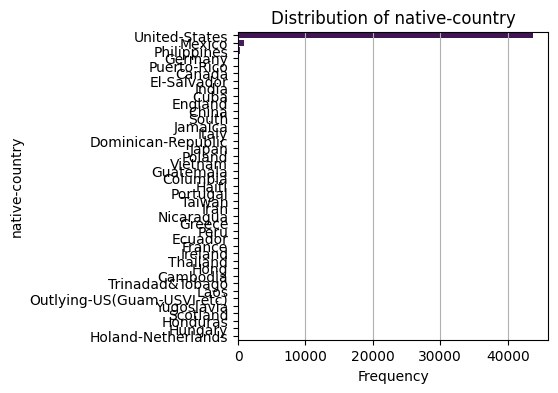

In [41]:
plot_hist_categorical(df, 'native-country')

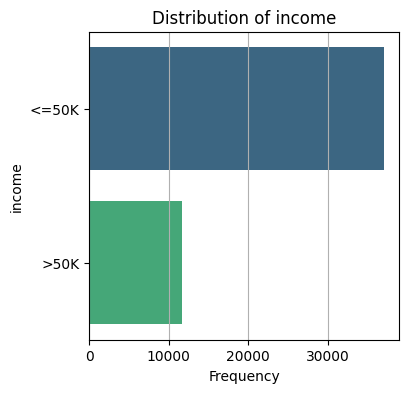

In [42]:
plot_hist_categorical(df, 'income')

в 1/3 доход более 50K. Имеем дело с несбалансированным датасетом. Необходимо применить техники балансировки

## 4. Изучение взаимосвязей между признаками

### 4.1 Общая матрица корреляций

interval columns not set, guessing: ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']


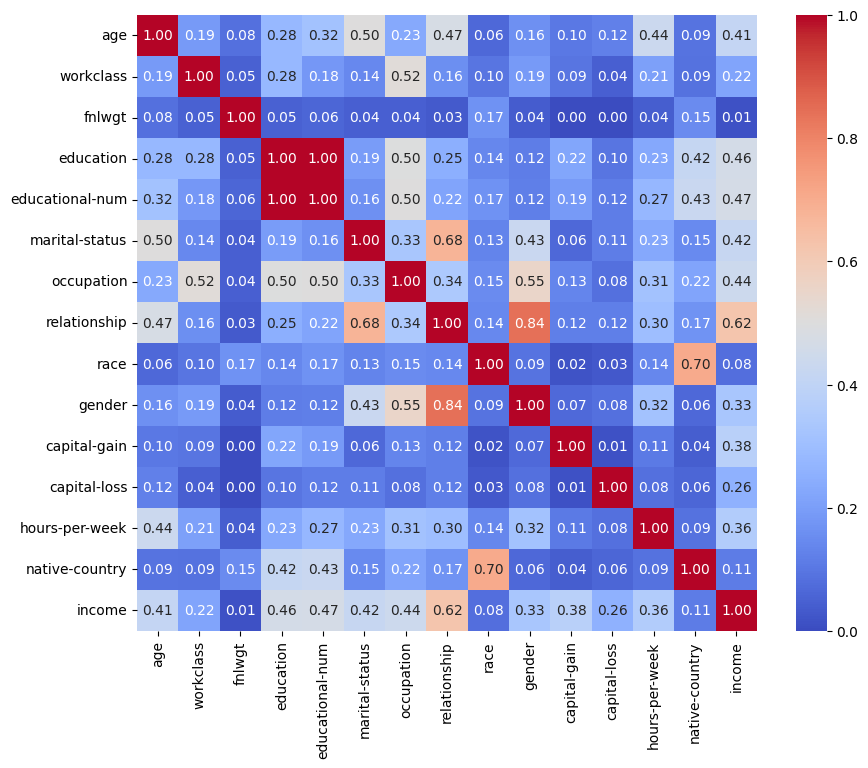

In [43]:
plot_phik(df)

In [44]:
# удаляем столбец educational-num, поскольку он дублирует educational
df = df.drop(columns=['educational-num'])

Наиболее высокие значения корреляции (>0.5):
- occupation vs workclass
- relationship vs marital-status 
- gender vs relationship	  
- native-country vs race 
- income vs relationship


### 4.2 Подробное изучение корреляций между выбранными парами

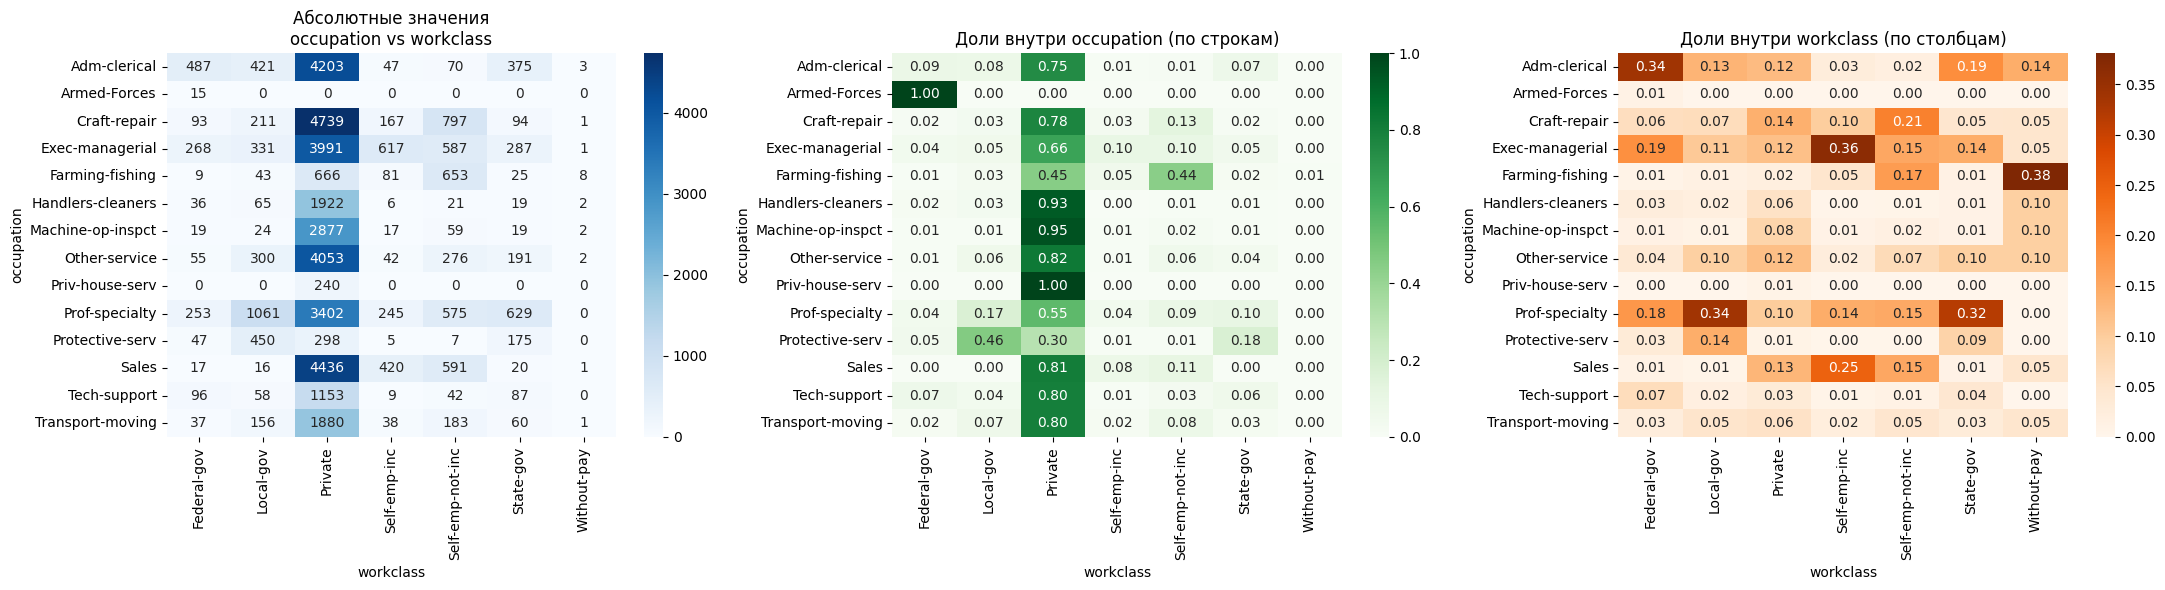

In [45]:
plot_categorical_relationship(df, 'occupation', 'workclass')

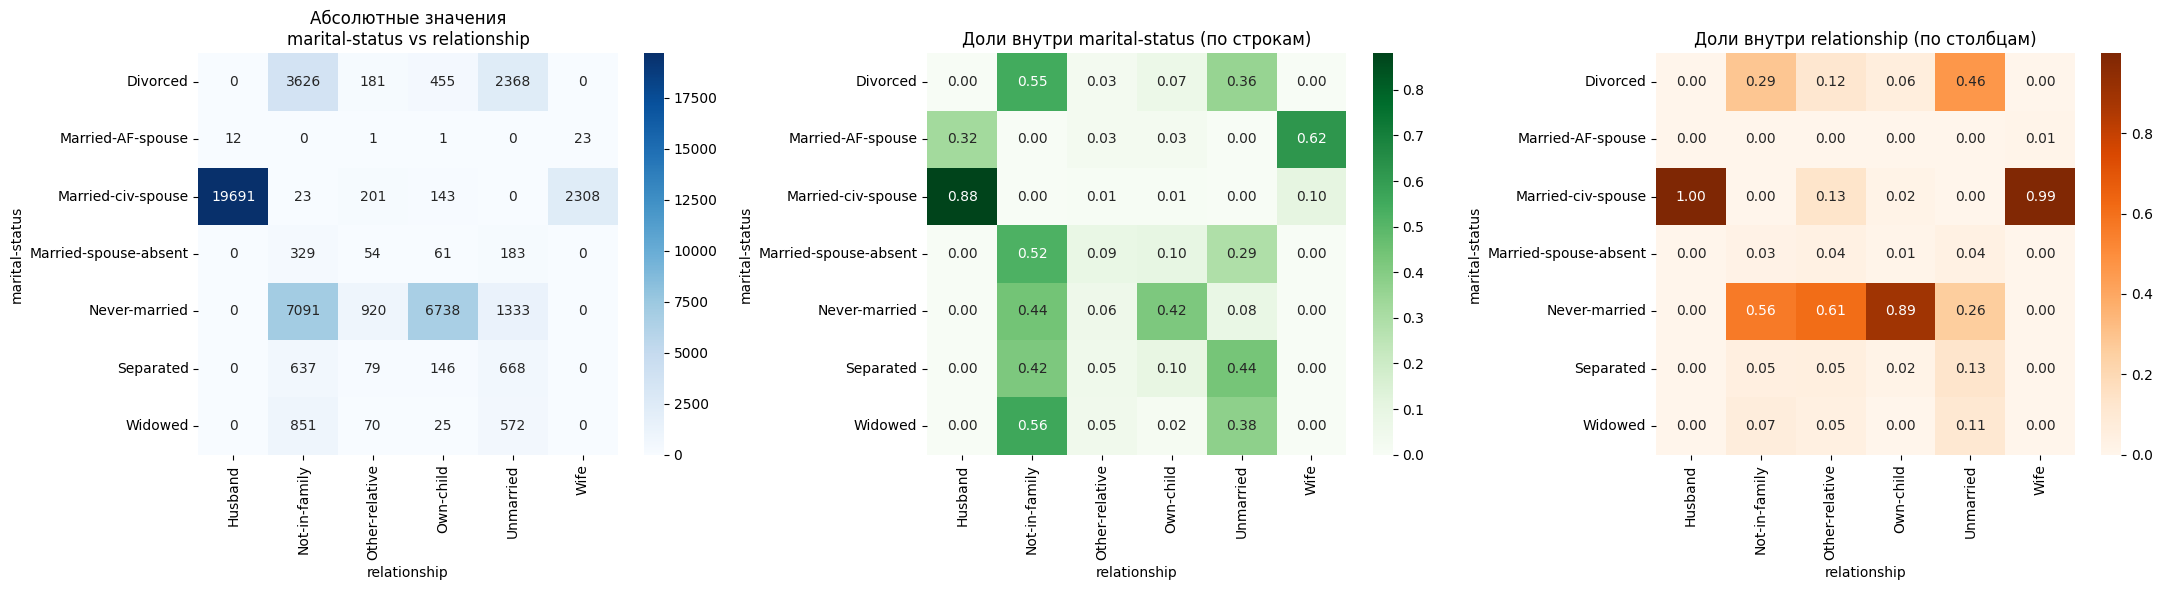

In [46]:
plot_categorical_relationship(df, 'marital-status', 'relationship')

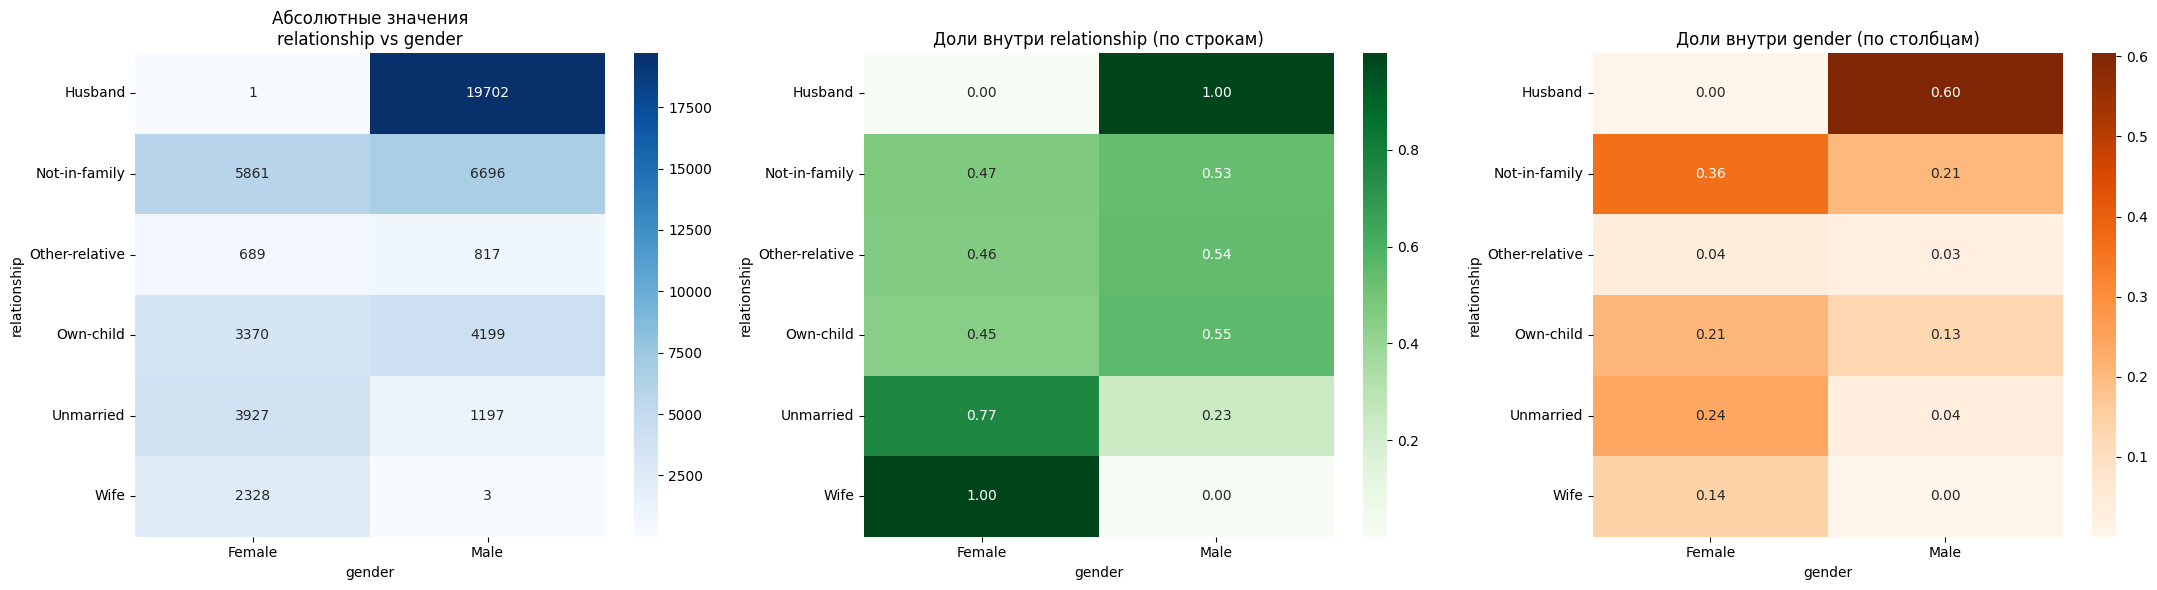

In [47]:
plot_categorical_relationship(df, 'relationship', 'gender')

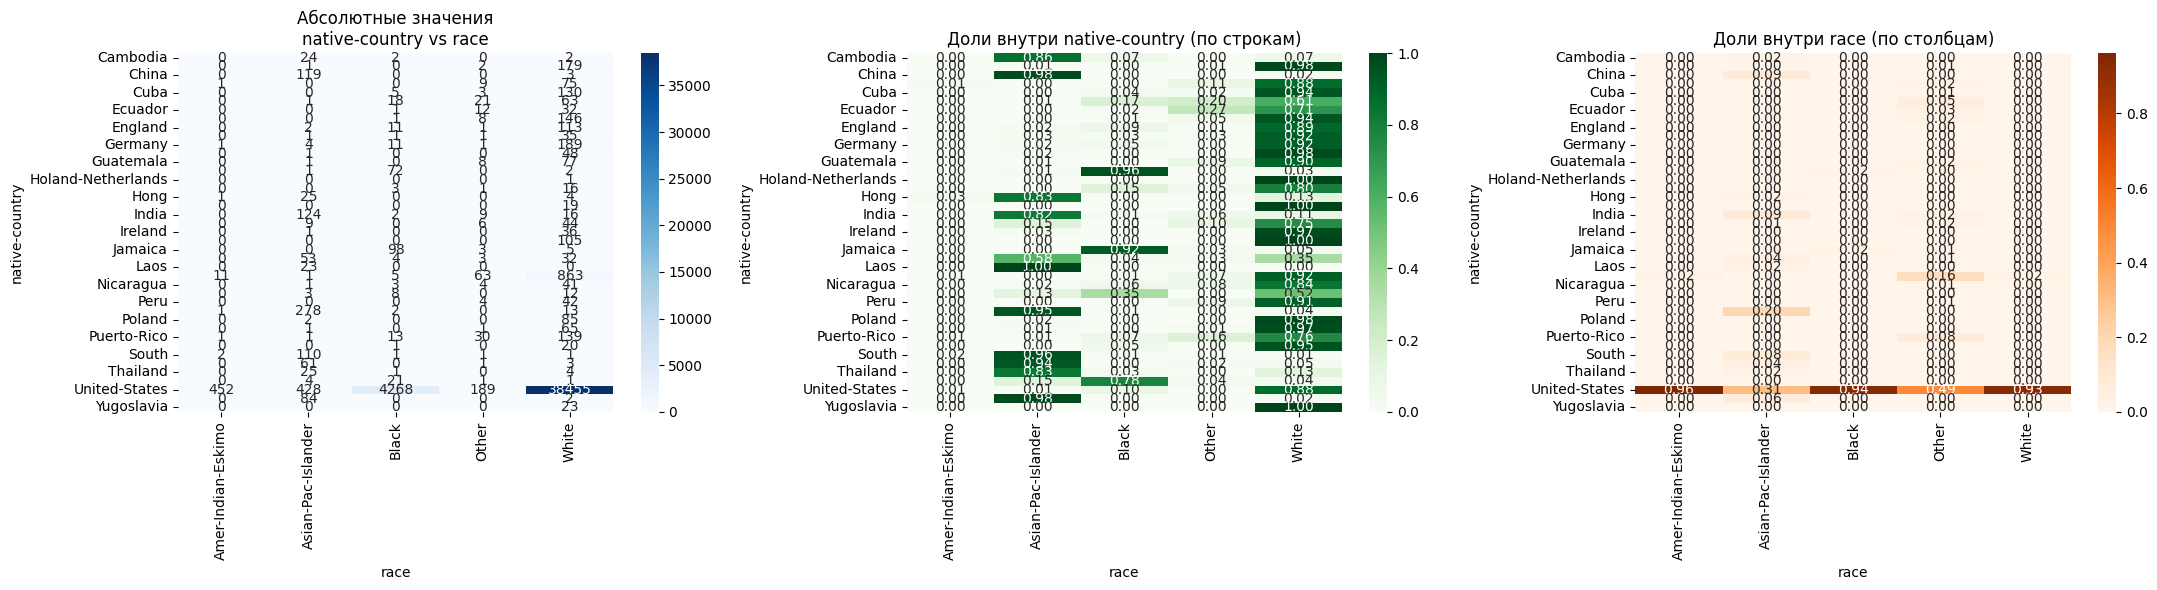

In [48]:
plot_categorical_relationship(df, 'native-country', 'race')

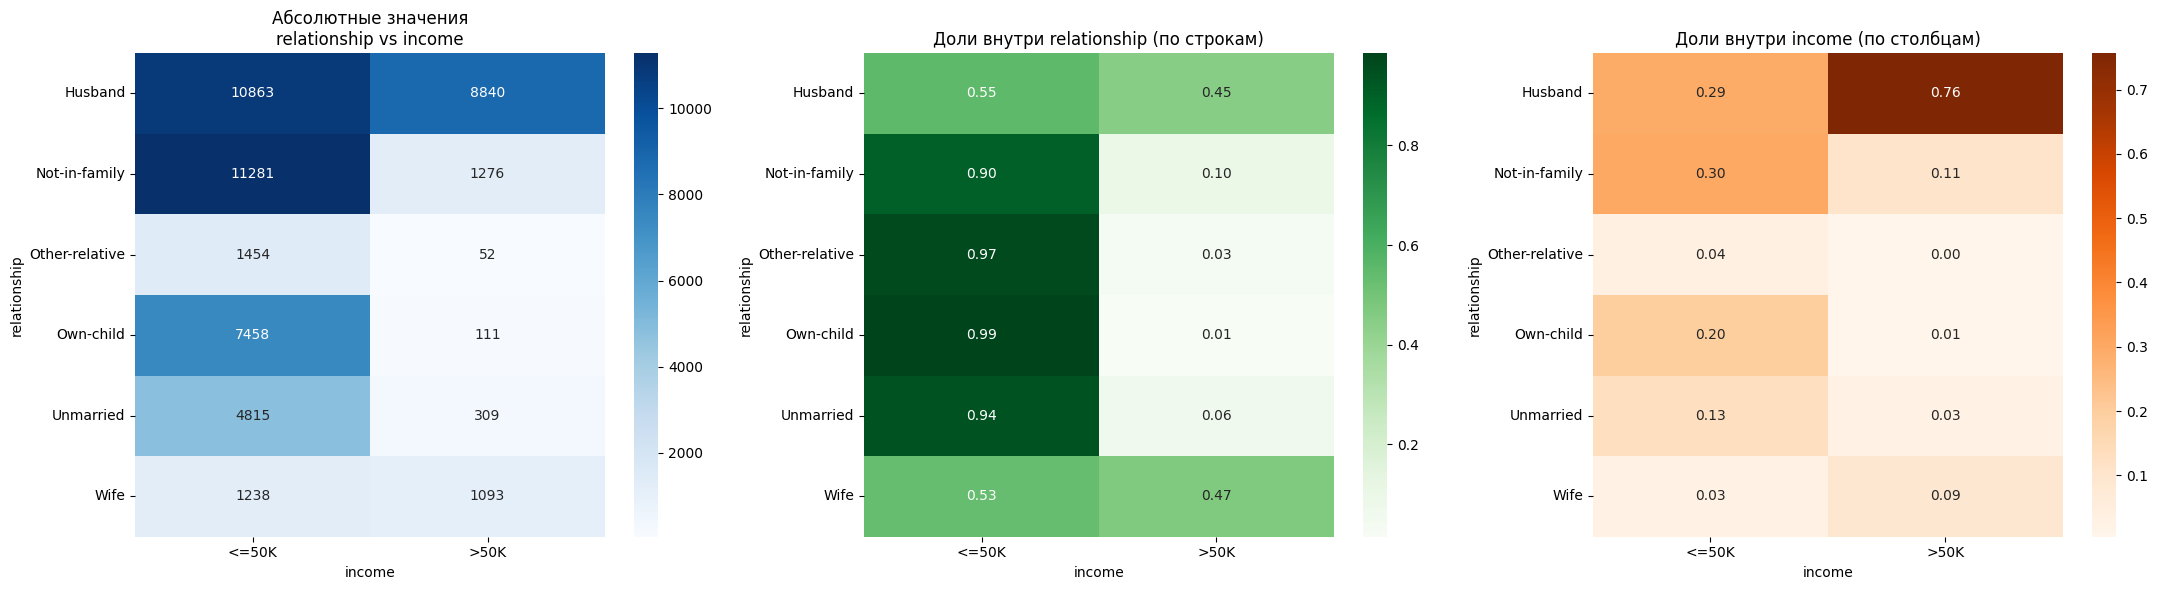

In [49]:
plot_categorical_relationship(df, 'relationship', 'income')


Можно сдедать вывод что чаще мужчины в браке зарабатывают >50K чем остальные категории

## 5. Препроцессинг данных

### 5.1 Общие преобразования

In [50]:
df_preprocessed = df.copy()

In [51]:
df_preprocessed['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [52]:
# Кодирование таргета
df_preprocessed['income'] = np.where(df_preprocessed['income'] == '>50K', 1, 0)

In [53]:
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48790 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48790 non-null  int64 
 1   workclass       45995 non-null  object
 2   fnlwgt          48790 non-null  int64 
 3   education       48790 non-null  object
 4   marital-status  48790 non-null  object
 5   occupation      45985 non-null  object
 6   relationship    48790 non-null  object
 7   race            48790 non-null  object
 8   gender          48790 non-null  object
 9   capital-gain    48790 non-null  int64 
 10  capital-loss    48790 non-null  int64 
 11  hours-per-week  48790 non-null  int64 
 12  native-country  47934 non-null  object
 13  income          48790 non-null  int64 
dtypes: int64(6), object(8)
memory usage: 5.6+ MB


### 5.2 Разбиение датасета 

In [54]:
# делим данные на признаки и таргет
X, y = divide_data(df_preprocessed, 'income')

In [55]:
# Разбиваем данные на train и test с соотношением 80 на 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=SEED, 
    stratify=y  
)

In [56]:
X_train

,age,workclass,fnlwgt,education,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
13116,44,Self-emp-not-inc,460259,Bachelors,Married-civ-spouse,Sales,Husband,White,Male,0,0,50,United-States
12057,22,State-gov,125010,Bachelors,Never-married,Prof-specialty,Own-child,White,Female,0,0,20,United-States
41063,29,Local-gov,188909,Bachelors,Never-married,Prof-specialty,Own-child,Black,Female,0,0,42,United-States
25025,22,Local-gov,134181,HS-grad,Never-married,Handlers-cleaners,Other-relative,White,Male,0,0,50,United-States
4130,50,Private,240374,Masters,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1783,48,Private,154430,Bachelors,Never-married,Exec-managerial,Not-in-family,White,Female,0,0,35,United-States
26793,37,Private,100508,HS-grad,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States
26779,74,Self-emp-not-inc,119129,HS-grad,Married-civ-spouse,Sales,Husband,White,Male,0,2149,20,United-States
891,45,Private,370261,Bachelors,Divorced,Exec-managerial,Not-in-family,White,Female,0,0,40,United-States


In [57]:
X_train_preprocessed = X_train.copy()

In [58]:
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation', 'relationship','race', 'gender', 'native-country']
numeric_cols = ['age', 'fnlwgt', 'capital-gain', 'capital-loss', 'hours-per-week']



### 5.3 Обработка пропущенных значений

In [59]:
X_train_preprocessed.isnull().sum()

age                  0
workclass         2233
fnlwgt               0
education            0
marital-status       0
occupation        2241
relationship         0
race                 0
gender               0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     674
dtype: int64

In [60]:

# пропуски в этих колонках будут заполняться наиболее частыми значениями
most_frequent_cat_cols = ['workclass', 'occupation', 'native-country']

# заменяем пропуски на самое частое значение
most_frequent_imputer = SimpleImputer(strategy='most_frequent')

# обрабатываем категориальные колонки
X_train_preprocessed[most_frequent_cat_cols] = most_frequent_imputer.fit_transform(X_train_preprocessed[most_frequent_cat_cols])

# Убеждаемся, что типы данных не поменялись
X_train_preprocessed.info()



<class 'pandas.core.frame.DataFrame'>
Index: 39032 entries, 13116 to 20252
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             39032 non-null  int64 
 1   workclass       39032 non-null  object
 2   fnlwgt          39032 non-null  int64 
 3   education       39032 non-null  object
 4   marital-status  39032 non-null  object
 5   occupation      39032 non-null  object
 6   relationship    39032 non-null  object
 7   race            39032 non-null  object
 8   gender          39032 non-null  object
 9   capital-gain    39032 non-null  int64 
 10  capital-loss    39032 non-null  int64 
 11  hours-per-week  39032 non-null  int64 
 12  native-country  39032 non-null  object
dtypes: int64(5), object(8)
memory usage: 4.2+ MB


In [61]:
# убедимся, что пропусков больше нет
X_train_preprocessed.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
marital-status    0
occupation        0
relationship      0
race              0
gender            0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
dtype: int64

### 5.4 Кодирование категориальных переменных

In [62]:
# Собираем уникальные значения из каждой колонки
category_orders = [X_train_preprocessed[col].unique().tolist() 
                   for col in categorical_cols]


In [63]:
# все категории
category_orders

[['Self-emp-not-inc',
  'State-gov',
  'Local-gov',
  'Private',
  'Self-emp-inc',
  'Federal-gov',
  'Without-pay',
  'Never-worked'],
 ['Bachelors',
  'HS-grad',
  'Masters',
  '10th',
  'Some-college',
  'Prof-school',
  '7th-8th',
  '9th',
  'Assoc-voc',
  '12th',
  '11th',
  'Assoc-acdm',
  '1st-4th',
  'Doctorate',
  '5th-6th',
  'Preschool'],
 ['Married-civ-spouse',
  'Never-married',
  'Widowed',
  'Divorced',
  'Separated',
  'Married-spouse-absent',
  'Married-AF-spouse'],
 ['Sales',
  'Prof-specialty',
  'Handlers-cleaners',
  'Exec-managerial',
  'Other-service',
  'Adm-clerical',
  'Farming-fishing',
  'Transport-moving',
  'Craft-repair',
  'Tech-support',
  'Protective-serv',
  'Machine-op-inspct',
  'Priv-house-serv',
  'Armed-Forces'],
 ['Husband',
  'Own-child',
  'Other-relative',
  'Not-in-family',
  'Wife',
  'Unmarried'],
 ['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo', 'Other'],
 ['Male', 'Female'],
 ['United-States',
  'Philippines',
  'South',
  

In [64]:
# Ставим категории в нужный порядок
category_orders = [
    # workclass
    ['Federal-gov', 'Local-gov', 'Never-worked', 'Private', 
     'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay'],
    
    # education
    ['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 
     'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 
     'Masters', 'Preschool', 'Prof-school', 'Some-college'],
     
    # marital-status
    ['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 
     'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed'],
     
    # occupation
    ['Adm-clerical', 'Armed-Forces', 'Craft-repair', 
     'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 
     'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 
     'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 
     'Transport-moving'],
     
    # relationship
    ['Husband', 'Not-in-family', 'Other-relative', 'Own-child', 
     'Unmarried', 'Wife'],
     
    # race
    ['Amer-Indian-Eskimo', 'Asian-Pac-Islander', 'Black', 'Other', 'White'],
    
    # sex
    ['Male', 'Female'],
    
    # native-country
    ['Cambodia', 'Canada', 'China', 'Columbia', 'Cuba', 
     'Dominican-Republic', 'Ecuador', 'El-Salvador', 'England', 
     'France', 'Germany', 'Greece', 'Guatemala', 'Haiti', 
     'Holand-Netherlands', 'Honduras', 'Hong', 'Hungary', 'India', 
     'Iran', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Laos', 
     'Mexico', 'Nicaragua', 'Outlying-US(Guam-USVI-etc)', 'Peru', 
     'Philippines', 'Poland', 'Portugal', 'Puerto-Rico', 'Scotland', 
     'South', 'Taiwan', 'Thailand', 'Trinadad&Tobago', 'United-States', 
     'Vietnam', 'Yugoslavia']
]

In [65]:
encoder = OrdinalEncoder(categories=category_orders)
X_train_preprocessed[categorical_cols] = encoder.fit_transform(X_train_preprocessed[categorical_cols])

In [66]:
X_train_preprocessed

,age,workclass,fnlwgt,education,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
13116,44,5.0,460259,9.0,2.0,11.0,0.0,4.0,0.0,0,0,50,38.0
12057,22,6.0,125010,9.0,4.0,9.0,3.0,4.0,1.0,0,0,20,38.0
41063,29,1.0,188909,9.0,4.0,9.0,3.0,2.0,1.0,0,0,42,38.0
25025,22,1.0,134181,11.0,4.0,5.0,2.0,4.0,0.0,0,0,50,38.0
4130,50,3.0,240374,12.0,2.0,3.0,0.0,4.0,0.0,0,0,50,38.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1783,48,3.0,154430,9.0,4.0,3.0,1.0,4.0,1.0,0,0,35,38.0
26793,37,3.0,100508,11.0,2.0,2.0,0.0,4.0,0.0,0,0,40,38.0
26779,74,5.0,119129,11.0,2.0,11.0,0.0,4.0,0.0,0,2149,20,38.0
891,45,3.0,370261,9.0,0.0,3.0,1.0,4.0,1.0,0,0,40,38.0


### 5.3 Итоговый пайплайн для препроцессинга


In [67]:

# Создаем предобработчик данных в виде последовательного Pipeline
preprocessor = Pipeline([
    # Шаг 1: Заполнение пропусков
    ('nan_remover', ColumnTransformer(
        [
            ('most_frequent_cat', SimpleImputer(strategy='most_frequent'), most_frequent_cat_cols),
        ],
        remainder='passthrough',  # колонки, не указанные в трансформерах, передаются без изменений
        verbose_feature_names_out=False  # не добавлять префиксы к именам колонок
    )),
    
    # Шаг 2: Кодирование категориальных признаков
    ('transformations', ColumnTransformer(
        [('encoder', OrdinalEncoder(categories=category_orders), categorical_cols)],
        remainder='passthrough',  # числовые колонки передаются без изменений
        verbose_feature_names_out=False
    ))
])

# Устанавливаем вывод в формате pandas DataFrame (для sklearn версии 1.0 и выше)
preprocessor.set_output(transform="pandas")

,steps,"[('nan_remover', ...), ('transformations', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('most_frequent_cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [68]:
# обучаем и применяем наш пайплайн к тестовой выборке
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_train_preprocessed = pd.DataFrame(X_train_preprocessed, index=X_train.index)

In [69]:
# смотрим на результат работы пайплайна
X_train_preprocessed 

,workclass,education,marital-status,occupation,relationship,race,gender,native-country,age,fnlwgt,capital-gain,capital-loss,hours-per-week
13116,5.0,9.0,2.0,11.0,0.0,4.0,0.0,38.0,44,460259,0,0,50
12057,6.0,9.0,4.0,9.0,3.0,4.0,1.0,38.0,22,125010,0,0,20
41063,1.0,9.0,4.0,9.0,3.0,2.0,1.0,38.0,29,188909,0,0,42
25025,1.0,11.0,4.0,5.0,2.0,4.0,0.0,38.0,22,134181,0,0,50
4130,3.0,12.0,2.0,3.0,0.0,4.0,0.0,38.0,50,240374,0,0,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1783,3.0,9.0,4.0,3.0,1.0,4.0,1.0,38.0,48,154430,0,0,35
26793,3.0,11.0,2.0,2.0,0.0,4.0,0.0,38.0,37,100508,0,0,40
26779,5.0,11.0,2.0,11.0,0.0,4.0,0.0,38.0,74,119129,0,2149,20
891,3.0,9.0,0.0,3.0,1.0,4.0,1.0,38.0,45,370261,0,0,40


In [70]:
# снова проверим типы данных. Мы видим, что все столбцы теперь числовые, что нам и требовалось
X_train_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39032 entries, 13116 to 20252
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   workclass       39032 non-null  float64
 1   education       39032 non-null  float64
 2   marital-status  39032 non-null  float64
 3   occupation      39032 non-null  float64
 4   relationship    39032 non-null  float64
 5   race            39032 non-null  float64
 6   gender          39032 non-null  float64
 7   native-country  39032 non-null  float64
 8   age             39032 non-null  int64  
 9   fnlwgt          39032 non-null  int64  
 10  capital-gain    39032 non-null  int64  
 11  capital-loss    39032 non-null  int64  
 12  hours-per-week  39032 non-null  int64  
dtypes: float64(8), int64(5)
memory usage: 4.2 MB


## 6. Построение базовой модели (baseline)

In [71]:
X_test_preprocessed = preprocessor.transform(X_test)
X_test_preprocessed

,workclass,education,marital-status,occupation,relationship,race,gender,native-country,age,fnlwgt,capital-gain,capital-loss,hours-per-week
30204,3.0,11.0,4.0,7.0,1.0,1.0,0.0,23.0,34,149943,0,0,40
26624,5.0,9.0,0.0,2.0,1.0,2.0,0.0,38.0,39,331481,0,1669,60
17977,3.0,11.0,2.0,3.0,5.0,4.0,1.0,38.0,49,32212,0,0,43
20164,5.0,0.0,2.0,6.0,0.0,4.0,0.0,38.0,63,159715,0,0,40
10557,1.0,15.0,2.0,3.0,0.0,4.0,0.0,38.0,34,108247,0,0,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32755,5.0,14.0,2.0,9.0,0.0,4.0,0.0,38.0,54,83311,0,0,30
31456,3.0,9.0,4.0,0.0,1.0,4.0,1.0,38.0,28,199903,0,0,20
13987,3.0,2.0,4.0,9.0,4.0,4.0,1.0,38.0,20,358355,0,0,35
25067,5.0,11.0,6.0,2.0,1.0,4.0,1.0,38.0,57,217692,0,0,38


In [72]:
X_test_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9758 entries, 30204 to 33893
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   workclass       9758 non-null   float64
 1   education       9758 non-null   float64
 2   marital-status  9758 non-null   float64
 3   occupation      9758 non-null   float64
 4   relationship    9758 non-null   float64
 5   race            9758 non-null   float64
 6   gender          9758 non-null   float64
 7   native-country  9758 non-null   float64
 8   age             9758 non-null   int64  
 9   fnlwgt          9758 non-null   int64  
 10  capital-gain    9758 non-null   int64  
 11  capital-loss    9758 non-null   int64  
 12  hours-per-week  9758 non-null   int64  
dtypes: float64(8), int64(5)
memory usage: 1.0 MB


In [73]:
X_test_preprocessed.isnull().sum()

workclass         0
education         0
marital-status    0
occupation        0
relationship      0
race              0
gender            0
native-country    0
age               0
fnlwgt            0
capital-gain      0
capital-loss      0
hours-per-week    0
dtype: int64

In [74]:
feature_names = X_test_preprocessed.columns.to_list()

In [75]:
feature_names

['workclass',
 'education',
 'marital-status',
 'occupation',
 'relationship',
 'race',
 'gender',
 'native-country',
 'age',
 'fnlwgt',
 'capital-gain',
 'capital-loss',
 'hours-per-week']

### 6.1 Dummy Classifier

c:\Users\Kalita\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Kalita\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


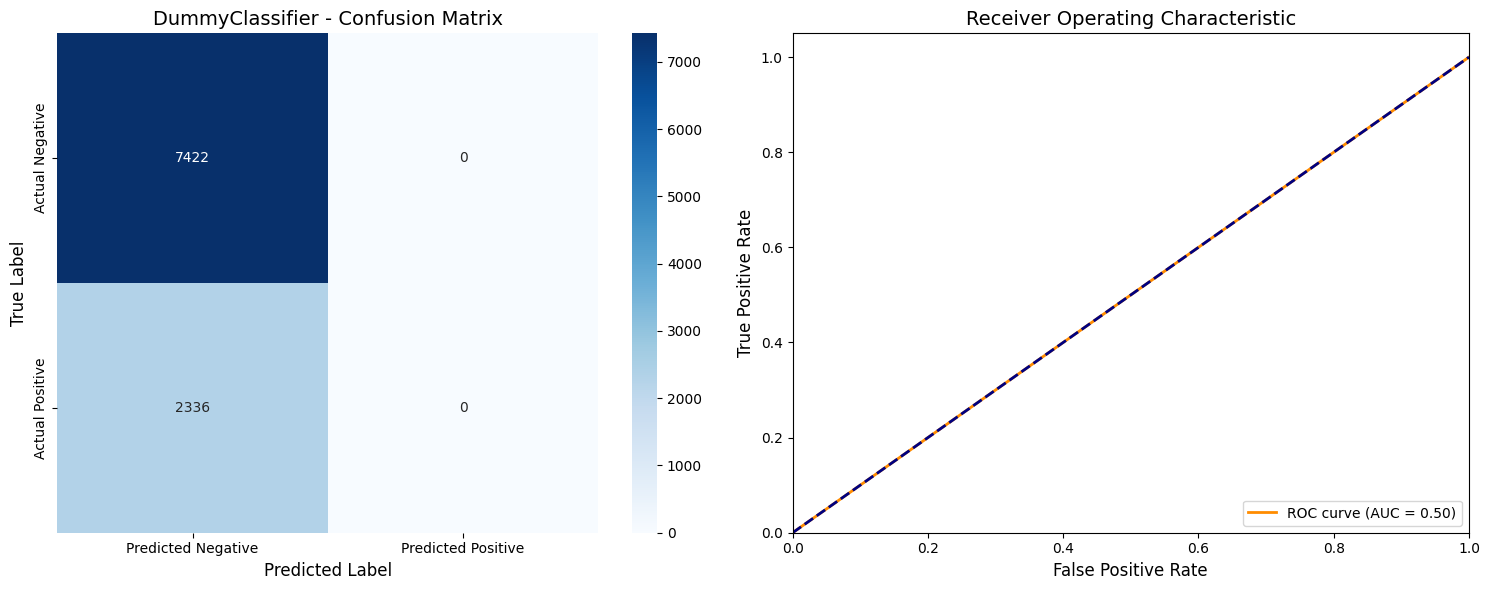


                 DUMMYCLASSIFIER EVALUATION                 

MAIN METRICS:
   Metric  Value
  ROC AUC 0.5000
 F1 Score 0.4320
Precision 0.3803
   Recall 0.5000
 Accuracy 0.7606


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.000000     0.0
Negative   0.760607     1.0



In [76]:
# Задаем и обучаем модель
dummy_classifier = DummyClassifier(random_state=SEED, strategy='most_frequent')
dummy_classifier.fit(X_train_preprocessed, y_train)

# Получаем предсказания
y_pred = dummy_classifier.predict(X_test_preprocessed) # предсказываем номер класса
y_probs = dummy_classifier.predict_proba(X_test_preprocessed)[:, 1] # предсказываем вероятность (необходима для построения ROC кривой)

# Считаем метрики для модели и выводим графики
dummy_classifier_metrics = evaluate_classification(
    y_test=y_test,
    y_pred=y_pred,
    y_probs=y_probs,
    model_name="DummyClassifier"
)

### 6.2 Логистическая регрессия

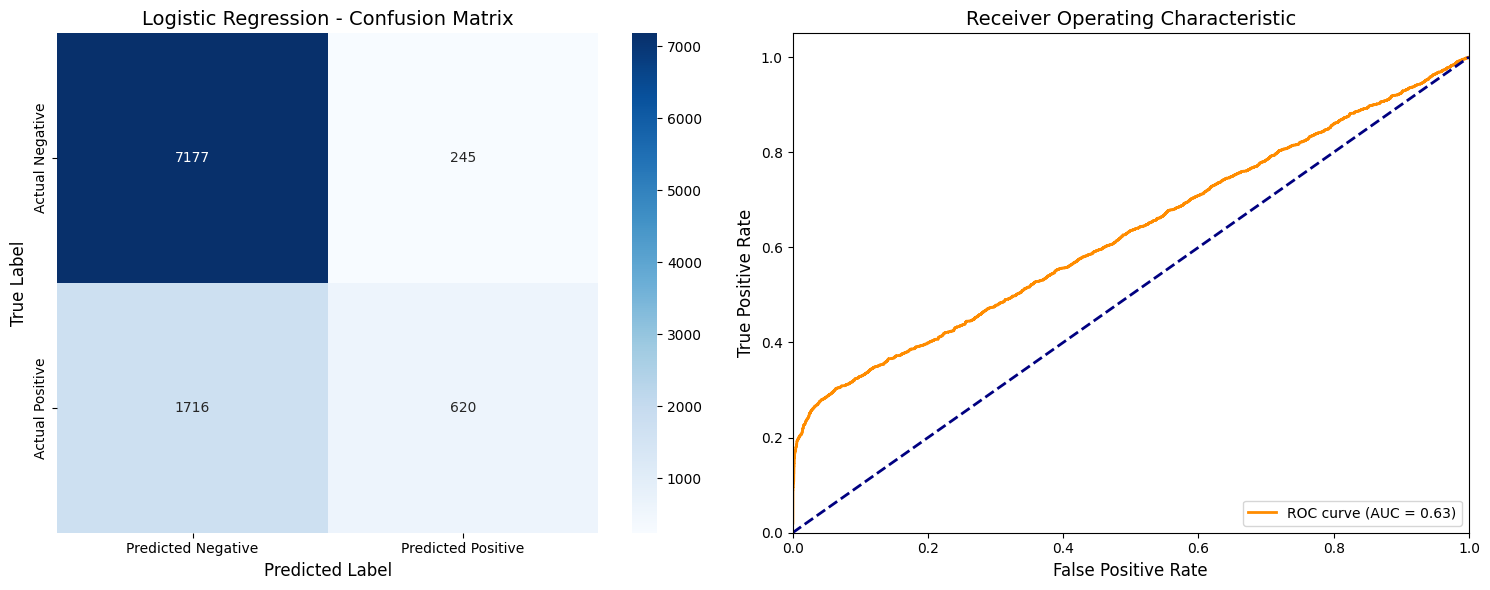


               LOGISTIC REGRESSION EVALUATION               

MAIN METRICS:
   Metric  Value
  ROC AUC 0.6282
 F1 Score 0.6336
Precision 0.7619
   Recall 0.6162
 Accuracy 0.7990


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.716763 0.265411
Negative   0.807039 0.966990



In [77]:
log_reg = LogisticRegression(random_state=SEED, max_iter=1000, solver='liblinear')
log_reg.fit(X_train_preprocessed, y_train)

y_pred = log_reg.predict(X_test_preprocessed)
y_probs = log_reg.predict_proba(X_test_preprocessed)[:, 1]  

log_reg_metrics = evaluate_classification(
    y_test=y_test,
    y_pred=y_pred,
    y_probs=y_probs,
    model_name="Logistic Regression"
)

c:\Users\Kalita\Desktop\offer\Prediction-of-adult-incomes\plots.py:290: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


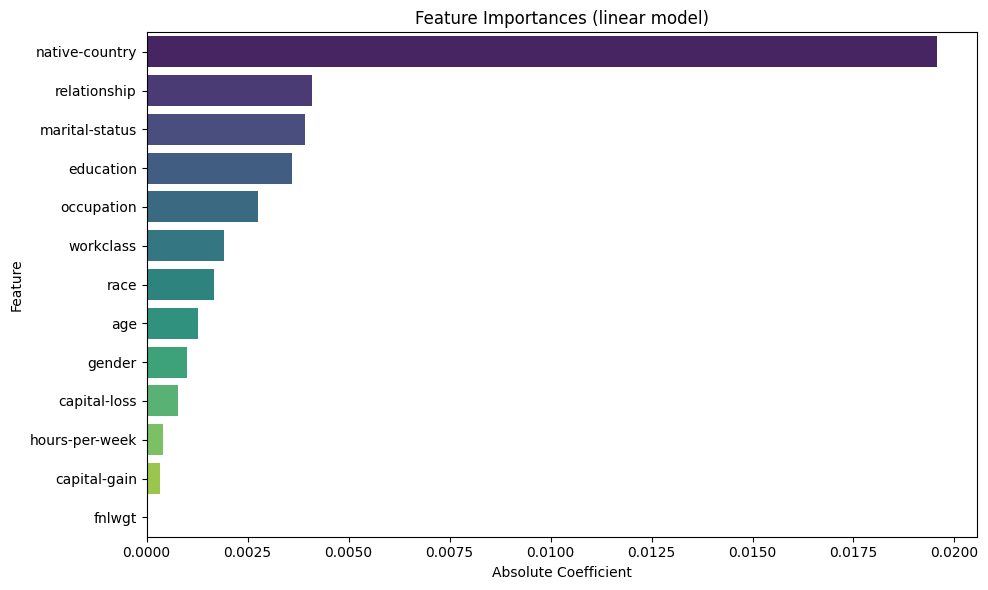

,Feature,Importance
7,native-country,0.019570
4,relationship,0.004088
2,marital-status,0.003920
1,education,0.003602
3,occupation,0.002761
0,workclass,0.001906
5,race,0.001667
8,age,0.001264
6,gender,0.001007
11,capital-loss,0.000784


In [78]:
# Построим гистограмму важностей для каждой фичи
plot_feature_importance(log_reg, feature_names)

### 6.3 Дерево решений

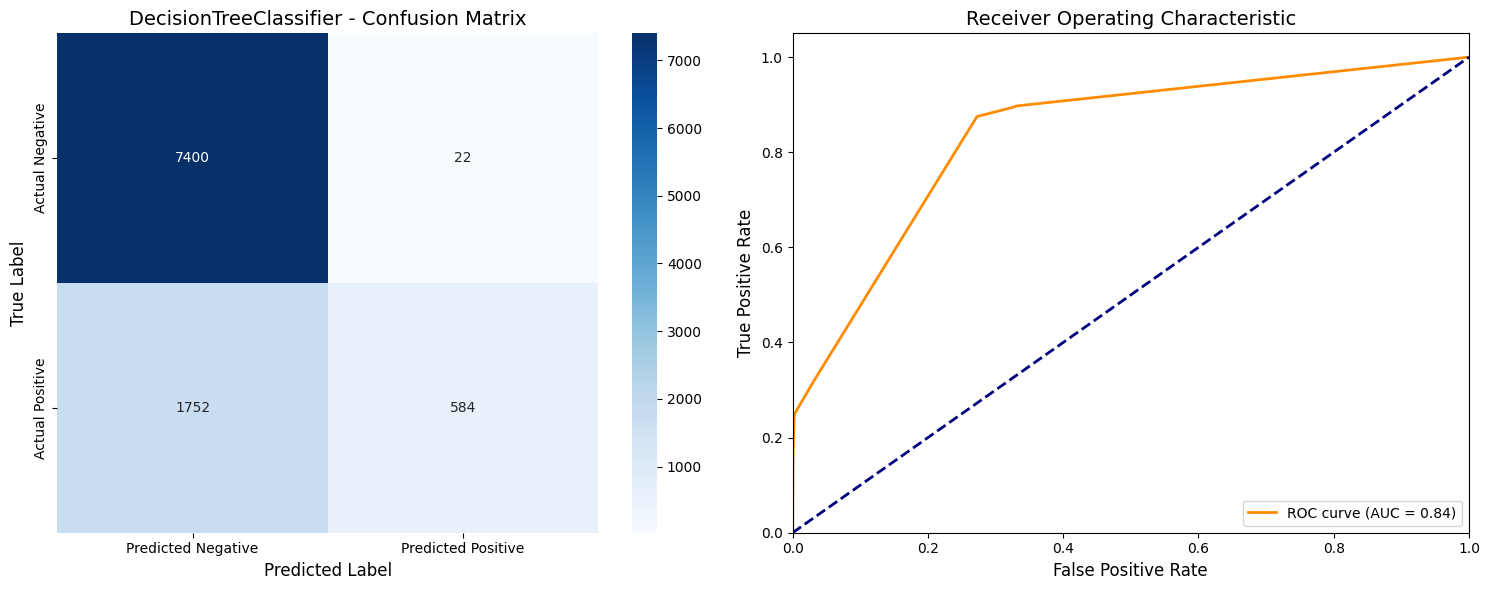


             DECISIONTREECLASSIFIER EVALUATION              

MAIN METRICS:
   Metric  Value
  ROC AUC 0.8391
 F1 Score 0.6450
Precision 0.8861
   Recall 0.6235
 Accuracy 0.8182


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.963696 0.250000
Negative   0.808566 0.997036



In [81]:
decision_tree = DecisionTreeClassifier(random_state=SEED, max_depth=4)
decision_tree.fit(X_train_preprocessed, y_train)

y_pred = decision_tree.predict(X_test_preprocessed)
y_probs = decision_tree.predict_proba(X_test_preprocessed)[:, 1]  # For ROC curve

decision_tree_metrics = evaluate_classification(
    y_test=y_test,
    y_pred=y_pred,
    y_probs=y_probs,
    model_name="DecisionTreeClassifier"
)

c:\Users\Kalita\Desktop\offer\Prediction-of-adult-incomes\plots.py:290: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


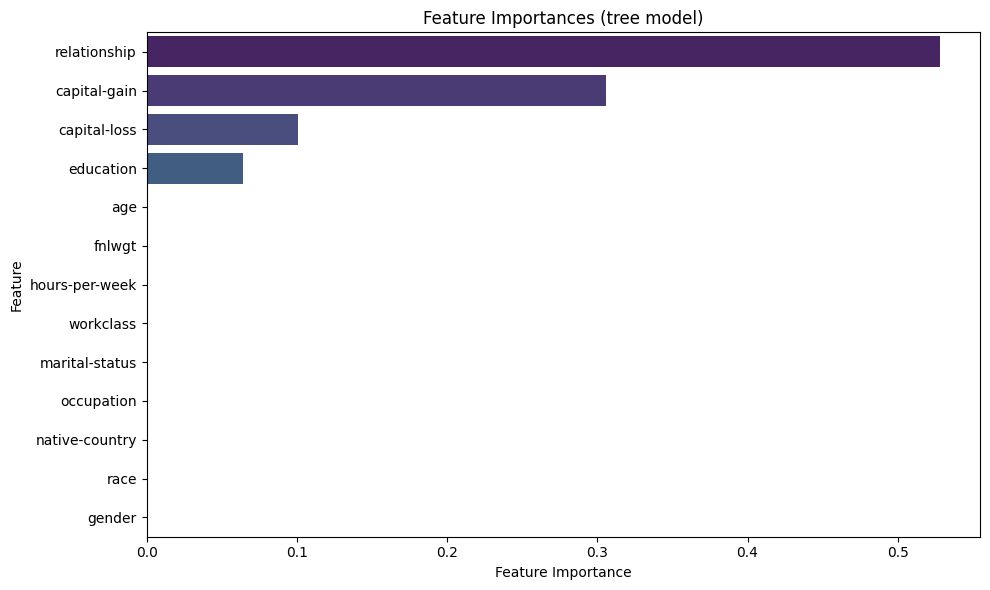

,Feature,Importance
4,relationship,0.528346
10,capital-gain,0.305505
11,capital-loss,0.100516
1,education,0.063850
8,age,0.001224
9,fnlwgt,0.000507
12,hours-per-week,0.000053
0,workclass,0.000000
2,marital-status,0.000000
3,occupation,0.000000


In [82]:
plot_feature_importance(decision_tree, feature_names)

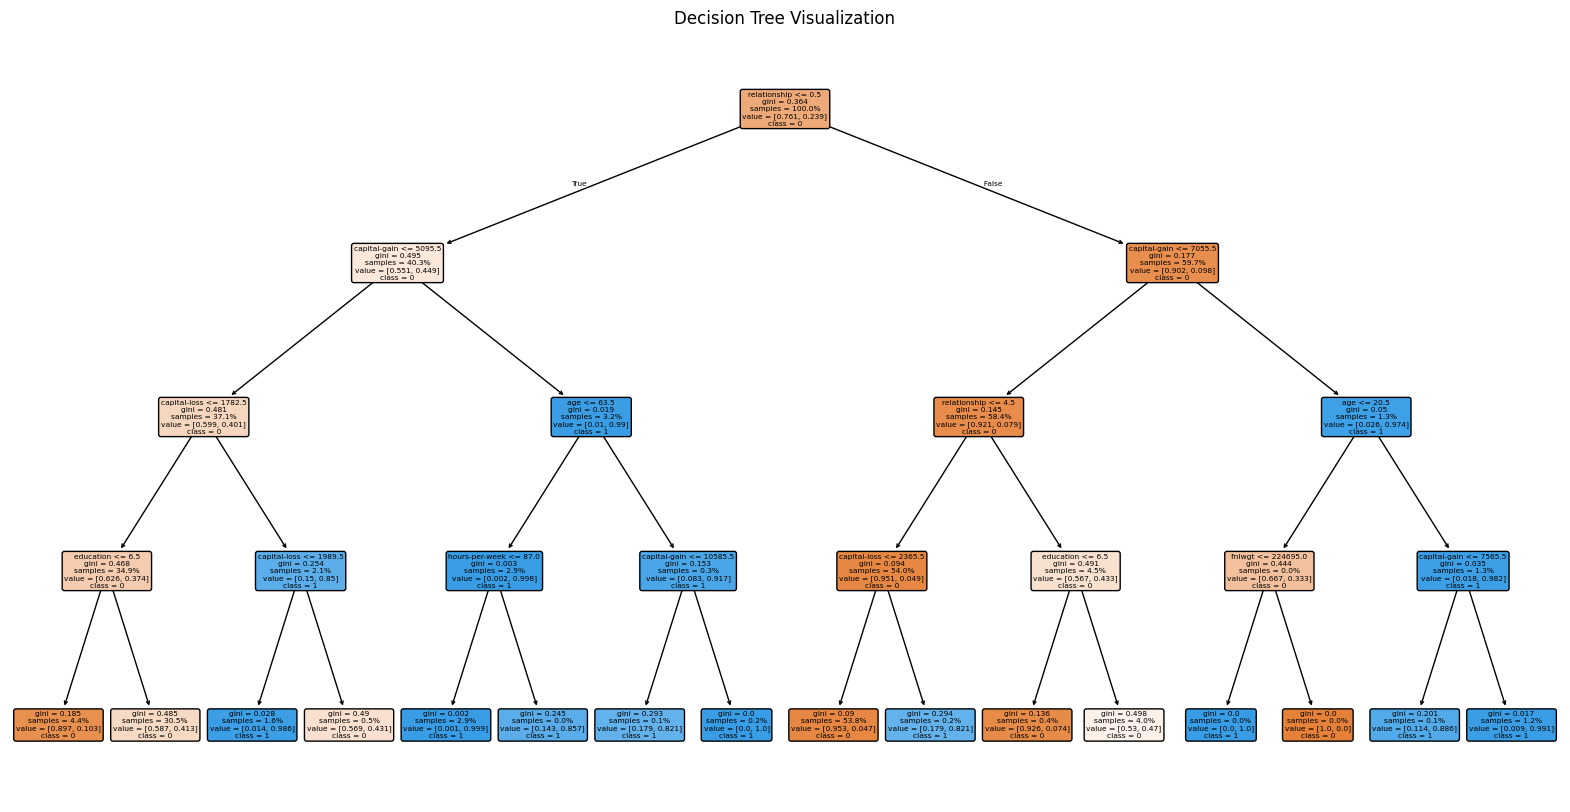

In [83]:
# Визуализируем наше дерево решений
visualize_decision_tree(decision_tree, feature_names, class_names=['0', '1'])

### 6.4 Случайный лес

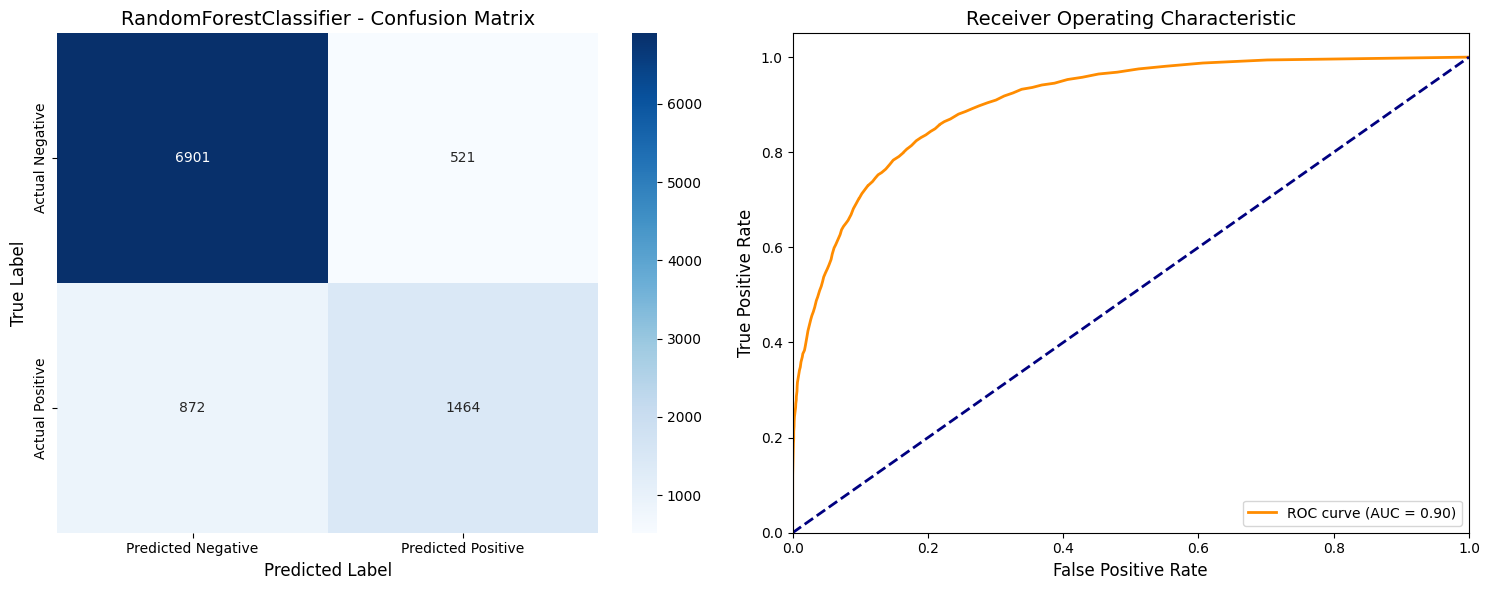


             RANDOMFORESTCLASSIFIER EVALUATION              

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9046
 F1 Score 0.7930
Precision 0.8127
   Recall 0.7783
 Accuracy 0.8572


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.737531 0.626712
Negative   0.887817 0.929803



In [84]:
# Train your model
random_forest = RandomForestClassifier(random_state=SEED)
random_forest.fit(X_train_preprocessed, y_train)

# Get predictions
y_pred = random_forest.predict(X_test_preprocessed)
y_probs = random_forest.predict_proba(X_test_preprocessed)[:, 1]  # For ROC curve

# Evaluate
random_forest_metrics = evaluate_classification(
    y_test=y_test,
    y_pred=y_pred,
    y_probs=y_probs,
    model_name="RandomForestClassifier"
)

c:\Users\Kalita\Desktop\offer\Prediction-of-adult-incomes\plots.py:290: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


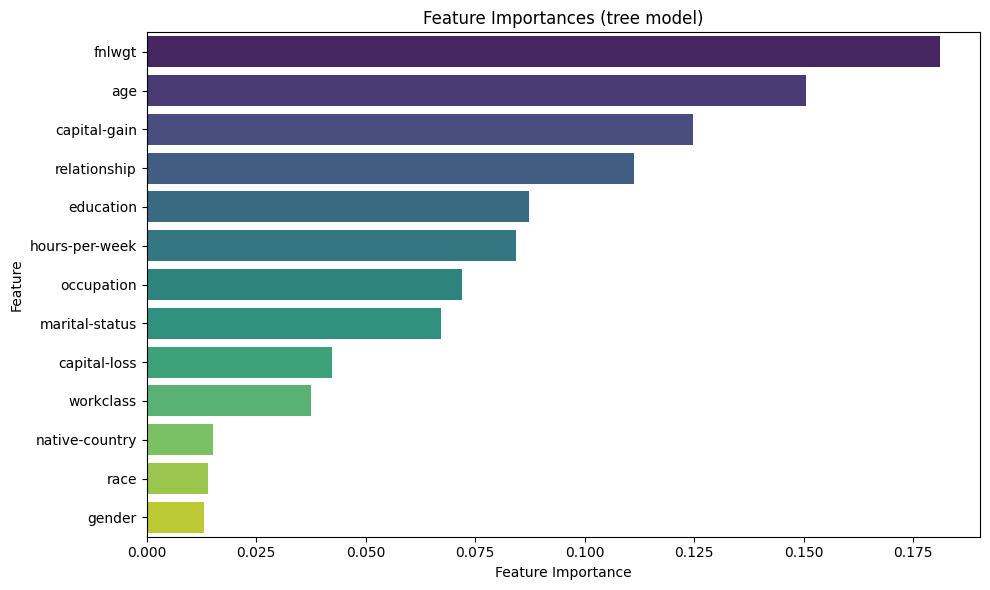

,Feature,Importance
9,fnlwgt,0.181205
8,age,0.150597
10,capital-gain,0.124659
4,relationship,0.111267
1,education,0.087209
12,hours-per-week,0.084294
3,occupation,0.071930
2,marital-status,0.067105
11,capital-loss,0.042226
0,workclass,0.037429


In [85]:
plot_feature_importance(random_forest, feature_names)

### 6.5 Градиентный бустинг

[LightGBM] [Info] Number of positive: 9345, number of negative: 29687
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002599 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 694
[LightGBM] [Info] Number of data points in the train set: 39032, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.239419 -> initscore=-1.155868
[LightGBM] [Info] Start training from score -1.155868


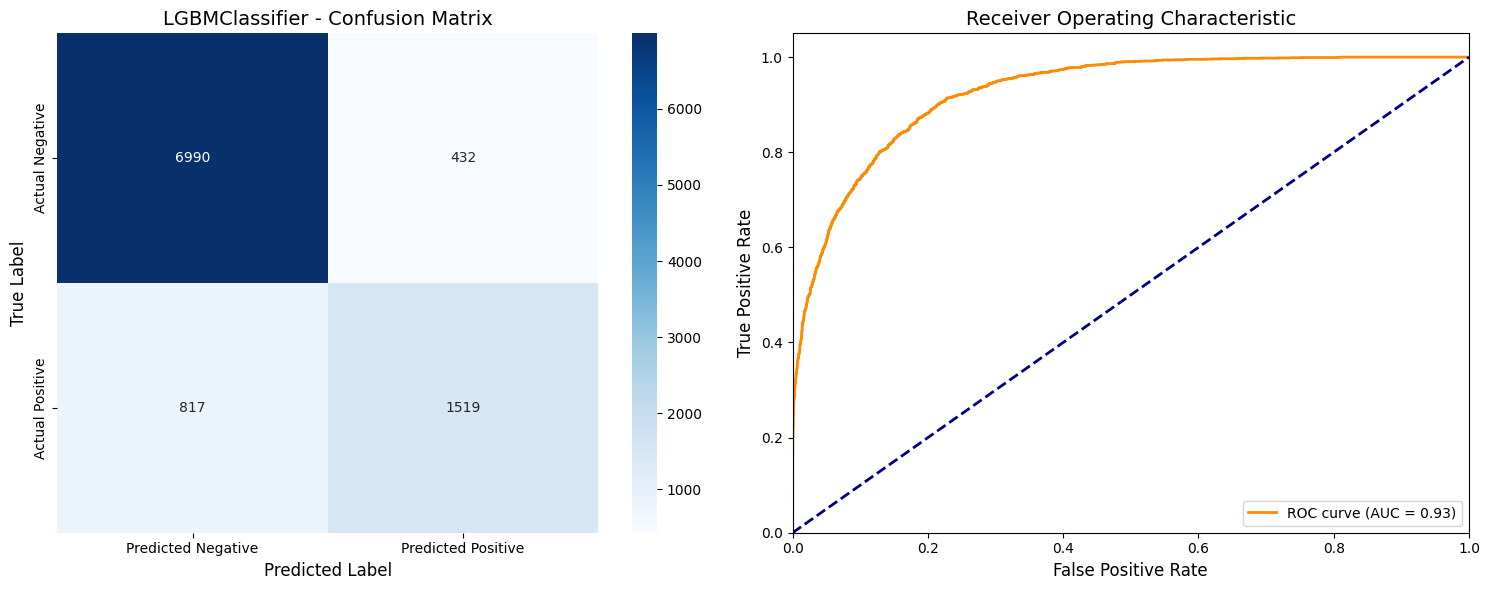


                 LGBMCLASSIFIER EVALUATION                  

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9262
 F1 Score 0.8133
Precision 0.8370
   Recall 0.7960
 Accuracy 0.8720


CLASSIFICATION REPORT:
   Class  Precision   Recall
Positive   0.778575 0.650257
Negative   0.895350 0.941795



In [86]:
# Train your model
lgbm = LGBMClassifier(random_state=SEED)
lgbm.fit(X_train_preprocessed, y_train)

# Get predictions
y_pred = lgbm.predict(X_test_preprocessed)
y_probs = lgbm.predict_proba(X_test_preprocessed)[:, 1]  # For ROC curve

# Evaluate
lgbm_metrics = evaluate_classification(
    y_test=y_test,
    y_pred=y_pred,
    y_probs=y_probs,
    model_name="LGBMClassifier"
)

c:\Users\Kalita\Desktop\offer\Prediction-of-adult-incomes\plots.py:290: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature',


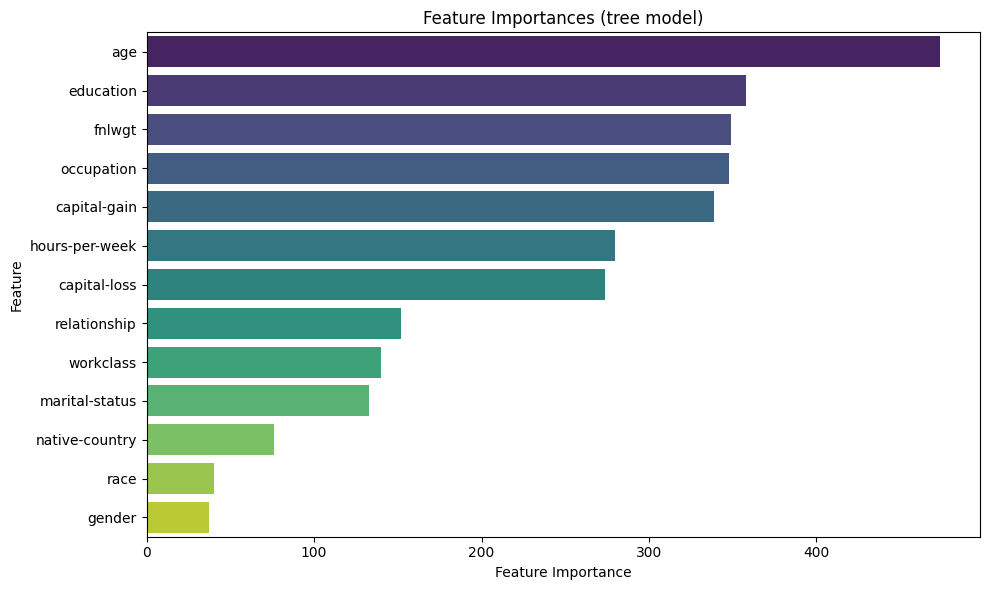

,Feature,Importance
8,age,474
1,education,358
9,fnlwgt,349
3,occupation,348
10,capital-gain,339
12,hours-per-week,280
11,capital-loss,274
4,relationship,152
0,workclass,140
2,marital-status,133


In [87]:
plot_feature_importance(lgbm, feature_names)

### 6.6 Финальное сравнение метрик

In [88]:
final_metrics = {
    'dummy_classifier': dummy_classifier_metrics,
    'log_reg': log_reg_metrics,
    'decision_tree': decision_tree_metrics,
    'random_forest': random_forest_metrics,
    'lgbm': lgbm_metrics
}

result = pd.DataFrame(final_metrics.values(), index=final_metrics.keys())
result

,ROC AUC,F1 Score,Precision,Recall,Accuracy
dummy_classifier,0.500000,0.432014,0.380303,0.500000,0.760607
log_reg,0.628247,0.633591,0.761901,0.616200,0.799037
decision_tree,0.839057,0.644987,0.886131,0.623518,0.818200
random_forest,0.904555,0.792973,0.812674,0.778258,0.857245
lgbm,0.926187,0.813320,0.836963,0.796026,0.872002


<Axes: >

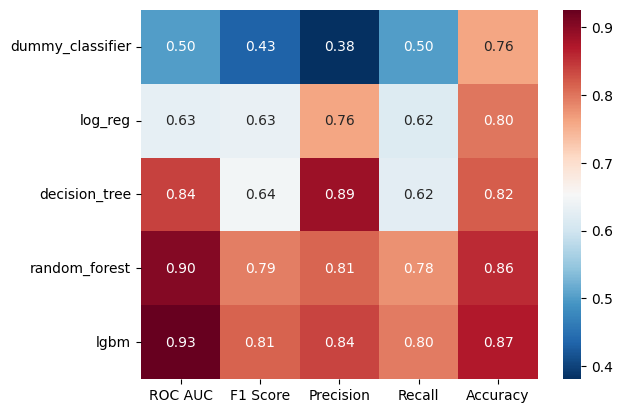

In [89]:
sns.heatmap(result, cmap='RdBu_r', annot=True, fmt=".2f")